# HW5

Naim El Rouwadi | Student ID: 261031398

## Setup

I use the professor's [Lecture 10 code](https://github.com/Ahmed-Bayoumy/MECH559/blob/d830247384368a08630adb207ce818c4b2eebed2/L10/L10_OMADS_tutorials.ipynb). The helper and its default options below are copied unchanged. I added the HW5 models, runs, and tables. Run all cells from the top. Questions 1 and 2 are done by hand in the homework.

In [1]:
# Run this once if these packages are missing (Python 3.12):
# %pip install OMADS==2610 samplerslib==2610.0 numpy==2.5.4 scipy==1.18.1 pandas==2.3.3 matplotlib==3.11.2

from pathlib import Path
import contextlib
import io
import time
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from OMADS import poll, search, mads
from IPython.display import display

POST_DIR = str(Path.cwd() / 'post_HW5')
Path(POST_DIR).mkdir(exist_ok=True)
plt.rcParams.update({'font.size': 10, 'figure.dpi': 130, 'axes.grid': True,
                     'grid.alpha': .2, 'savefig.bbox': 'tight'})
pd.set_option('display.max_colwidth', 140)
pd.set_option('display.precision', 9)
print({p: version(p) for p in ['OMADS', 'samplerslib', 'numpy', 'scipy', 'pandas', 'matplotlib']})

{'OMADS': '2610', 'samplerslib': '2610.0', 'numpy': '2.5.4', 'scipy': '1.18.1', 'pandas': '2.3.3', 'matplotlib': '3.11.2'}


In [2]:
BASE_OPTIONS = {"seed": 0, "budget": 1000, "tol": 1e-12, "display": False, "save_results": False,
                "check_cache": True, "store_cache": True, "rich_direction": True,
                "opportunistic": False, "is_verbose": False}
BASE_SEARCH = {"type": "sampling", "s_method": "ACTIVE", "ns": 10, "visualize": False}
SOLVERS = {"poll": poll, "search": search, "mads": mads}


def solve(blackbox, param, solver="mads", options=None, search_options=None):
    """Run an OMADS solver quietly; return (summary dict, history DataFrame, wall time)."""
    calls = []

    def logged_blackbox(x):                    # OMADS requires a single-argument callable
        out = blackbox(x)
        calls.append((list(x), out))
        return out

    data = {"evaluator": {"blackbox": logged_blackbox},
            "param": {"post_dir": POST_DIR, **param},
            "options": {**BASE_OPTIONS, **(options or {})},
            "search": {**BASE_SEARCH, **(search_options or {})}}
    tic = time.perf_counter()
    with contextlib.redirect_stdout(io.StringIO()):
        summary = SOLVERS[solver].main(data)[0]
    wall = time.perf_counter() - tic

    rows = []
    for x, (f, c) in calls:
        f = float(np.ravel(f)[0])
        h = float(np.sum(np.maximum(np.asarray(c, dtype=float), 0.0) ** 2))   # constraint violation
        rows.append({"x": x, "f": f, "h": h, "feasible": h == 0.0 and np.isfinite(f)})
    hist = pd.DataFrame(rows)
    hist["best feasible f"] = hist["f"].where(hist["feasible"]).cummin()
    return summary, hist, wall


def report(name, summary, hist, wall):
    return {"run": name, "fmin": summary["fmin"][0], "hmin": summary["hmin"],
            "xmin": np.round(summary["xmin"], 5).tolist(), "blackbox calls": len(hist), "time [s]": round(wall, 1)}

I use a separate log to save the original constraint values before OMADS changes its output. This only helps me check the results. A point is feasible when all constraints are nonpositive and it is inside the bounds. I label a constraint active when its absolute value is at most $10^{-4}$.

In [3]:
def get_run(name, blackbox, param, solver, budget):
    calls = []

    def audited_blackbox(x):
        out = blackbox(x)
        calls.append((list(x), float(out[0]), list(out[1])))
        return out

    summary, course_hist, wall = solve(
        audited_blackbox, param, solver=solver,
        options={'seed': 12345, 'budget': budget})
    rows = []
    for i, (x, f, c) in enumerate(calls, 1):
        h = float(np.sum(np.maximum(np.asarray(c), 0.0)**2))
        finite = np.isfinite(f) and np.all(np.isfinite(c))
        inside = np.all(np.array(x) >= param['lb']) and np.all(np.array(x) <= param['ub'])
        rows.append({'eval': i, 'x': x, 'f': f, 'c': c, 'h': h,
                     'feasible': bool(finite and inside and h == 0.0)})
    hist = pd.DataFrame(rows)
    hist['best feasible f'] = hist.f.where(hist.feasible).cummin().ffill()
    print(name, ':', len(hist), 'blackbox calls')
    return summary, hist, wall

def print_table(title, table):
    print(title)
    print(table.to_string(index=False, float_format=lambda x: f'{x:.10g}'))
    print()


def numerical_record(name, result, fstar, budget):
    summary, hist, wall = result
    feasible = hist[hist.feasible]
    best = feasible.loc[feasible.f.idxmin()].to_dict() if len(feasible) else None
    within = hist.iloc[:budget]
    wf = within[within.feasible]
    best_within = wf.loc[wf.f.idxmin()].to_dict() if len(wf) else None
    return {'name': name, 'summary': summary, 'best': best,
            'best_within_budget': best_within,
            'calls': len(hist), 'infeasible_calls': int((~hist.feasible).sum()),
            'first_feasible': int(feasible.iloc[0]['eval']) if len(feasible) else None,
            'near_active_1e-4': [i+1 for i,c in enumerate(best['c']) if abs(c)<=1e-4] if best else [],
            'relative_gap': (best['f']-fstar)/fstar if best else None,
            'wall_s': wall, 'requested_budget': budget}

def table_of_runs(names, reference, budget):
    rows=[]
    for name in names:
        r=numerical_record(name,runs[name],reference,budget)
        b=r['best']
        rows.append({'run':name,'x':b['x'] if b else None,'f':b['f'] if b else None,
                     'constraints':b['c'] if b else None,'h':b['h'] if b else None,
                     'near active':r['near_active_1e-4'],'calls':r['calls'],
                     'infeasible calls':r['infeasible_calls'],'first feasible call':r['first_feasible'],
                     'gap (%)':100*r['relative_gap'] if b else None})
    return pd.DataFrame(rows)

runs = {}

## Question 3

### 3(a)

In [4]:
def spring(x):
    d, D, N = map(float, x)
    f = (N + 2)*D*d*d
    if D == d:
        return [f, [np.inf]*4]
    c = [1 - D**3*N/(71785*d**4),
         (4*D**2-d*D)/(12566*(D*d**3-d**4)) + 1/(5108*d**2)-1,
         1 - 140.45*d/(D**2*N),
         (d+D)/1.5 - 1]
    return [float(f), list(map(float, c))]

SPRING_STARTS={'A':[.1,1.,10.], 'B':[.05,1.,2.], 'C':[.06,.5,10.]}
SPRING_LB,SPRING_UB=[.05,.25,2.],[2.,1.3,15.]
rows=[]
for label,x in SPRING_STARTS.items():
    f,c=spring(x); h=float(np.sum(np.maximum(c,0)**2))
    rows.append({'start':label,'x':x,'f':f,**{f'c{j+1}':v for j,v in enumerate(c)},'h':h,'feasible':h==0})
print_table('Starting points', pd.DataFrame(rows))


Starting points
start                 x      f            c1            c2       c3            c4           h  feasible
    A  [0.1, 1.0, 10.0]   0.12 -0.3930486871 -0.6355769857  -0.4045 -0.2666666667           0      True
    B  [0.05, 1.0, 2.0]   0.01  -3.457755799   1.725384606 -2.51125          -0.3 2.976952037     False
    C [0.06, 0.5, 10.0] 0.0216 -0.3436040577  -0.133409224  -2.3708 -0.6266666667           0      True



### 3(b)

In [5]:
spring_names=[]
for start,barrier in [('A','EB'),('A','PB'),('B','EB'),('B','PB')]:
    name=f'spring_{start}_{barrier}'
    param={'name':name,'baseline':SPRING_STARTS[start],'lb':SPRING_LB,'ub':SPRING_UB,
           'var_names':['d','D','N'],'scaling':10.0,'constraints_type':[barrier]*4}
    runs[name]=get_run(name,spring,param,'mads',2000)
    spring_names.append(name)
print_table('Spring results', table_of_runs(spring_names,.012665,2000))


spring_A_EB : 2001 blackbox calls
spring_A_PB : 2001 blackbox calls
spring_B_EB : 2001 blackbox calls
spring_B_PB : 2001 blackbox calls
Spring results
        run                                                             x             f                                                                                 constraints  h near active  calls  infeasible calls  first feasible call     gap (%)
spring_A_EB  [0.06897713526632288, 0.9326991122434265, 2.002763390493783] 0.01776281486 [-3.6403777992077835e-08, -3.516624746957575e-08, -4.5605035976620405, -0.3322158349935004]  0      [1, 2]   2001              1603                    1 40.25120304
spring_A_PB  [0.06872226088307798, 0.9216390983201563, 2.045223585097119] 0.01760752439  [-7.554632919237747e-09, -1.0804137806630365e-08, -4.555928004433448, -0.3397590938645104]  0      [1, 2]   2001              1737                    1  39.0250643
spring_B_EB  [0.0688795798458159, 0.9284558747895062, 2.0188862818758935] 0.01770304465 [-

The budget is set to 2000. OMADS checks the starting point twice, so the log has 2001 calls. Both runs from B first find a feasible point at call 98.

### 3(c)

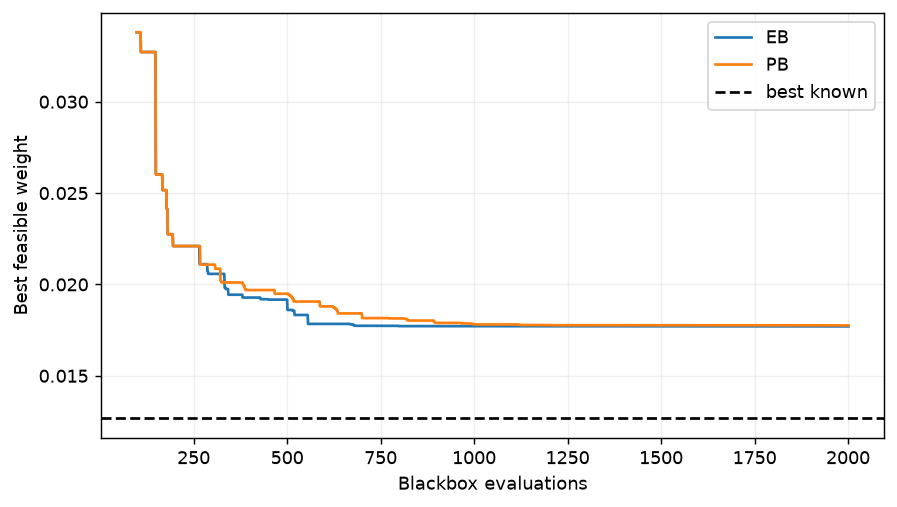

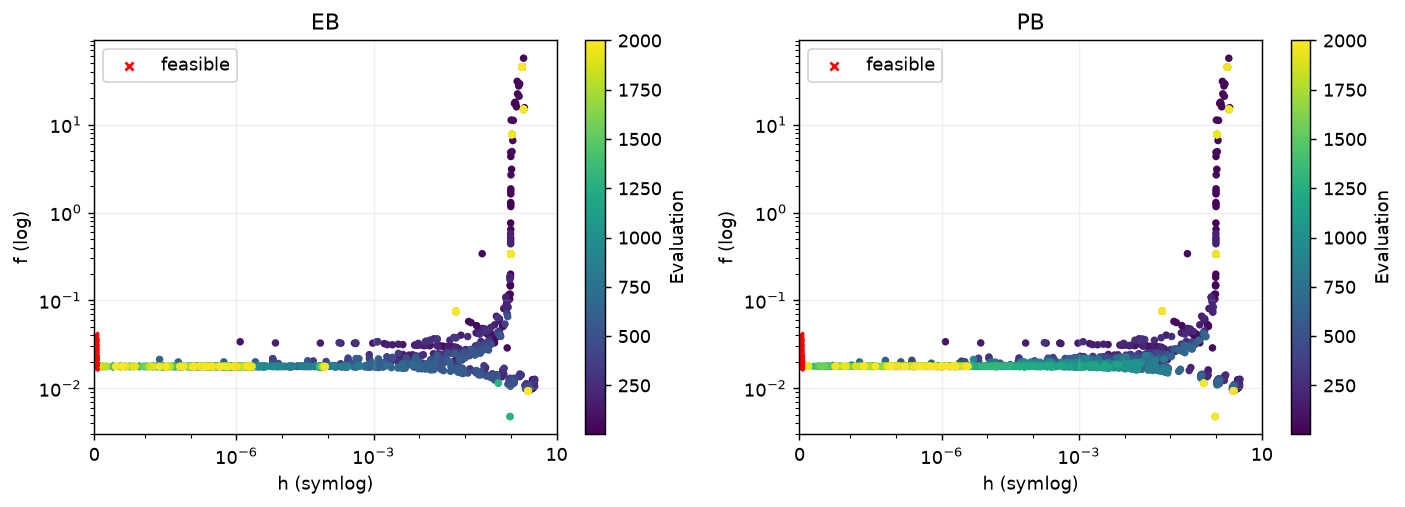

In [6]:
fig,ax=plt.subplots(figsize=(7,4))
for barrier in ['EB','PB']:
    hist=runs[f'spring_B_{barrier}'][1]
    if hist.feasible.any(): ax.plot(hist['eval'],hist['best feasible f'],label=barrier)
    else: ax.plot([],[],label=f'{barrier}: no feasible point')
ax.axhline(.012665,color='k',ls='--',label='best known')
ax.set(xlabel='Blackbox evaluations',ylabel='Best feasible weight')
ax.legend(); fig.tight_layout(); display(fig); plt.close(fig)
fig,axs=plt.subplots(1,2,figsize=(11,4))
for ax,barrier in zip(axs,['EB','PB']):
    hist=runs[f'spring_B_{barrier}'][1]
    z=hist.feasible.astype(bool)
    sc=ax.scatter(hist.loc[~z,'h'],hist.loc[~z,'f'],c=hist.loc[~z,'eval'],s=10,cmap='viridis')
    ax.scatter(hist.loc[z,'h'],hist.loc[z,'f'],marker='x',c='red',s=20,label='feasible')
    ax.set_xscale('symlog',linthresh=1e-8);ax.set_yscale('log')
    ax.set_xticks([0,1e-6,1e-3,10],['0',r'$10^{-6}$',r'$10^{-3}$','10'])
    ax.set_xlim(0,max(10,float(hist.h.max())*1.1))
    ax.set(xlabel='h (symlog)',ylabel='f (log)',title=barrier);ax.legend()
    fig.colorbar(sc,ax=ax,label='Evaluation')
fig.tight_layout();display(fig);plt.close(fig)


### 3(d)

In [7]:
name='spring_C_PB'
param={'name':name,'baseline':SPRING_STARTS['C'],'lb':SPRING_LB,'ub':SPRING_UB,
       'var_names':['d','D','N'],'scaling':10.0,'constraints_type':['PB']*4}
runs[name]=get_run(name,spring,param,'mads',2000)
print_table('PB from three starts', table_of_runs(['spring_A_PB','spring_B_PB','spring_C_PB'],.012665,2000))


spring_C_PB : 2001 blackbox calls
PB from three starts
        run                                                              x             f                                                                                constraints  h near active  calls  infeasible calls  first feasible call     gap (%)
spring_A_PB   [0.06872226088307798, 0.9216390983201563, 2.045223585097119] 0.01760752439 [-7.554632919237747e-09, -1.0804137806630365e-08, -4.555928004433448, -0.3397590938645104]  0      [1, 2]   2001              1737                    1  39.0250643
spring_B_PB  [0.06896983268670738, 0.9323810767382383, 2.0039647214580327] 0.01775832655 [-6.741571456636564e-08, -1.2431222939923714e-08, -4.560373218329757, -0.3324327270500361]  0      [1, 2]   2001              1669                   98 40.21576433
spring_C_PB [0.056451355167664585, 0.48247825138969347, 6.490798818296753] 0.01305494469 [-4.1453236887534217e-07, -2.1067130262508726e-08, -4.247379619370472, -0.640713595628428]  0    

Start C gives the lowest feasible weight. The budget is limited, and MADS does not guarantee the global minimum.

## Question 4

### 4(a)

In [8]:
def beam(x):
    w, l, t, b = map(float, x)
    P, L, E, G = 6000., 14., 30e6, 12e6
    f = 1.10471*w*w*l + 0.04811*t*b*(14+l)
    tp = P/(np.sqrt(2)*w*l)
    M = P*(L+l/2)
    R = np.sqrt(l*l/4 + ((w+t)/2)**2)
    J = 2*np.sqrt(2)*w*l*(l*l/12 + ((w+t)/2)**2)
    tpp = M*R/J
    tau = np.sqrt(tp*tp + 2*tp*tpp*l/(2*R) + tpp*tpp)
    sigma = 6*P*L/(b*t*t)
    delta = 4*P*L**3/(E*t**3*b)
    Pc = 4.013*E*np.sqrt(t*t*b**6/36)/L**2*(1-t/(2*L)*np.sqrt(E/(4*G)))
    c = [tau/13600-1, sigma/30000-1, w-b,
         (0.10471*w*w + 0.04811*t*b*(14+l))/5-1,
         0.125-w, delta/0.25-1, 1-Pc/P]
    return [float(f), list(map(float,c))]

BEAM_START=[1.,5.,5.,1.]
BEAM_LB,BEAM_UB=[.1]*4,[2.,10.,10.,2.]
f,c=beam(BEAM_START)
display(pd.DataFrame([{'f':f,**{f'c{j+1}':v for j,v in enumerate(c)},'h':float(np.sum(np.maximum(c,0)**2))}]))
assert np.all(np.array(c)<=0)


,f,c1,c2,c3,c4,c5,c6,c7,h
0,10.094,-0.773564956,-0.328,0.0,-0.064968,-0.875,-0.9297536,-72.26684333,0.0


### 4(b)

beam_poll_PB : 3000 blackbox calls
beam_mads_PB : 1566 blackbox calls
Beam results
         run                                                                               x           f                                                                                                                                                 constraints  h  near active  calls  infeasible calls  first feasible call         gap (%)
beam_poll_PB [0.9083541319357045, 1.0895254285866225, 4.298437485131148, 0.9092599355343178] 3.830435433 [-7.947920876993919e-09, -7.814996094701598e-09, -0.0009058035986133639, -0.4152549201421495, -0.7833541319357045, -0.8784054288587422, -47.44123894680046]  0       [1, 2]   3000              2276                    1     122.0732812
beam_mads_PB  [0.2057296397870232, 3.4704886656654708, 9.03662391036778, 0.2057296397870232] 1.724852309             [-1.4184986518728238e-11, -6.832867605055526e-12, 0.0, -0.6865967570699868, -0.08072963978702319, -0.9421612903394777, -1.

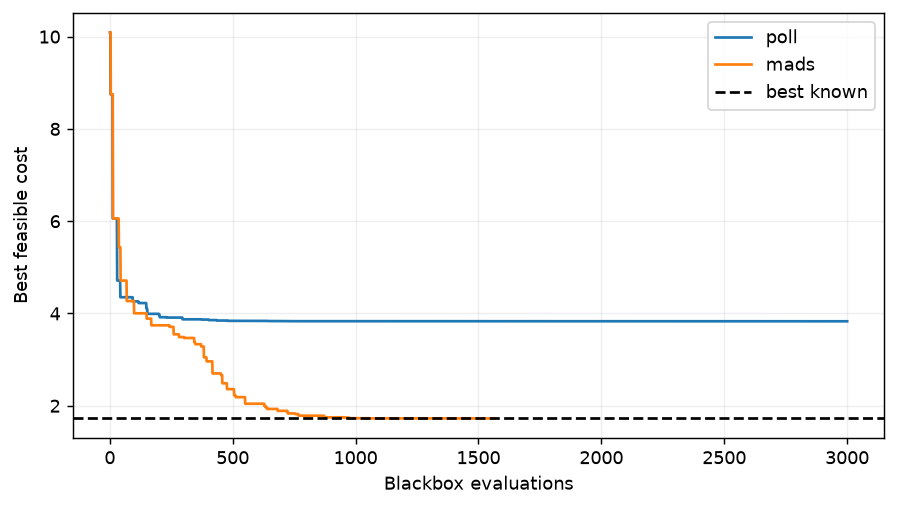

In [9]:
for solver in ['poll','mads']:
    name=f'beam_{solver}_PB'
    param={'name':name,'baseline':BEAM_START,'lb':BEAM_LB,'ub':BEAM_UB,
           'var_names':['h','l','t','b'],'scaling':10.0,'constraints_type':['PB']*7}
    runs[name]=get_run(name,beam,param,solver,3000)
print_table('Beam results', table_of_runs(['beam_poll_PB','beam_mads_PB'],1.724852,3000))
fig,ax=plt.subplots(figsize=(7,4))
for solver in ['poll','mads']:
    hist=runs[f'beam_{solver}_PB'][1]
    ax.plot(hist['eval'],hist['best feasible f'],label=solver)
ax.axhline(1.724852,color='k',ls='--',label='best known')
ax.set(xlabel='Blackbox evaluations',ylabel='Best feasible cost');ax.legend()
fig.tight_layout();display(fig);plt.close(fig)


### 4(c)

In [10]:
def run_nm(mode):
    calls=[]
    def fun(x):
        f,c=beam(x)
        h=float(np.maximum(c,0) @ np.maximum(c,0))
        val = (f if h==0 else np.inf) if mode=='EB' else f+1000*h
        calls.append({'eval':len(calls)+1,'x':list(x),'f':f,'c':c,'h':h,
                      'feasible':h==0.,'merit':val})
        return val
    res=minimize(fun,BEAM_START,method='Nelder-Mead',
                 bounds=list(zip(BEAM_LB,BEAM_UB)),options={'maxfev':3000})
    f,c=beam(res.x)
    hist=pd.DataFrame(calls)
    hist['best feasible f']=hist.f.where(hist.feasible).cummin().ffill()
    return {'x':res.x.tolist(),'f':f,'c':c,'h':float(np.sum(np.maximum(c,0)**2)),
            'merit':float(res.fun),'nfev':res.nfev,'nit':res.nit,
            'success':bool(res.success),'message':res.message,
            'near_active_1e-4':[i+1 for i,ci in enumerate(c) if abs(ci)<=1e-4]},hist

nm = {}
nm_histories = {}
for mode in ['EB', 'penalty']:
    nm[mode], nm_histories[mode] = run_nm(mode)
print_table('Nelder-Mead results', pd.DataFrame(nm).T.reset_index(names='method'))


Nelder-Mead results
 method                                                                               x           f                                                                                                                                                         c               h       merit nfev nit success                               message near_active_1e-4
     EB [0.27468356467381716, 4.535171801087861, 4.992162802680905, 0.8018615037593415] 3.947617865 [-1.5284429277784284e-10, -0.15931666641490394, -0.5271779390855243, -0.28449904272265747, -0.14968356467381716, -0.9119826069271665, -36.72560314586476]               0 3.947617865  671 365    True Optimization terminated successfully.              [1]
penalty             [0.12363235656232488, 10.0, 9.034543721714297, 0.20572620318604912] 2.314917312 [-0.23990364174299394, 0.00047726210315879314, -0.08209384662372424, -0.570467335451142, 0.00136764343767512, -0.942120362492415, 0.00020146628999717642] 2.138816354e-06 2.

### 4(d)

In [11]:
rows = []
for solver in ['poll', 'mads']:
    r = numerical_record(solver, runs[f'beam_{solver}_PB'], 1.724852, 3000)
    b = r['best']
    rows.append({'method': solver + ' PB', 'f': b['f'], 'h': b['h'],
                 'feasible': True, 'calls': r['calls'], 'near active': r['near_active_1e-4']})
for mode, r in nm.items():
    rows.append({'method': 'NM ' + mode, 'f': r['f'], 'h': r['h'],
                 'feasible': r['h'] == 0, 'calls': r['nfev'], 'near active': r['near_active_1e-4']})
print_table('Method comparison', pd.DataFrame(rows))


Method comparison
    method           f               h  feasible  calls  near active
   poll PB 3.830435433               0      True   3000       [1, 2]
   mads PB 1.724852309               0      True   1566 [1, 2, 3, 7]
     NM EB 3.947617865               0      True    671          [1]
NM penalty 2.314917312 2.138816354e-06     False   1079           []



MADS gives the lowest feasible cost. The penalty result still breaks some constraints, so I do not count it as a feasible design. A successful stop in Nelder-Mead does not prove that the constrained minimum was found.